
Experiments: 1


Optimizador: SGD
Dropout: 0

Iniciando entrenamiento... Opti -> SGD | Drop -> 0 | Batch size -> 100
Training time: 122.86 seconds

Peak GPU memory: 18.47 MB

Test CEL: 0.38093
Test accuracy: 87.78%

----------------- SGD-0.1/128-64/B100/D0/S42 -----------------


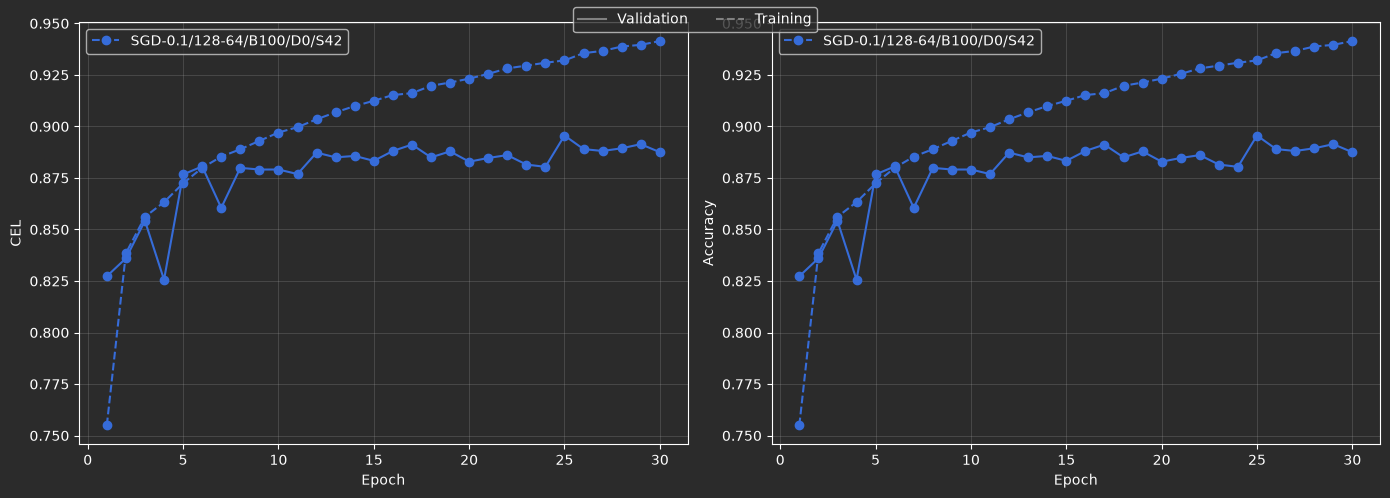

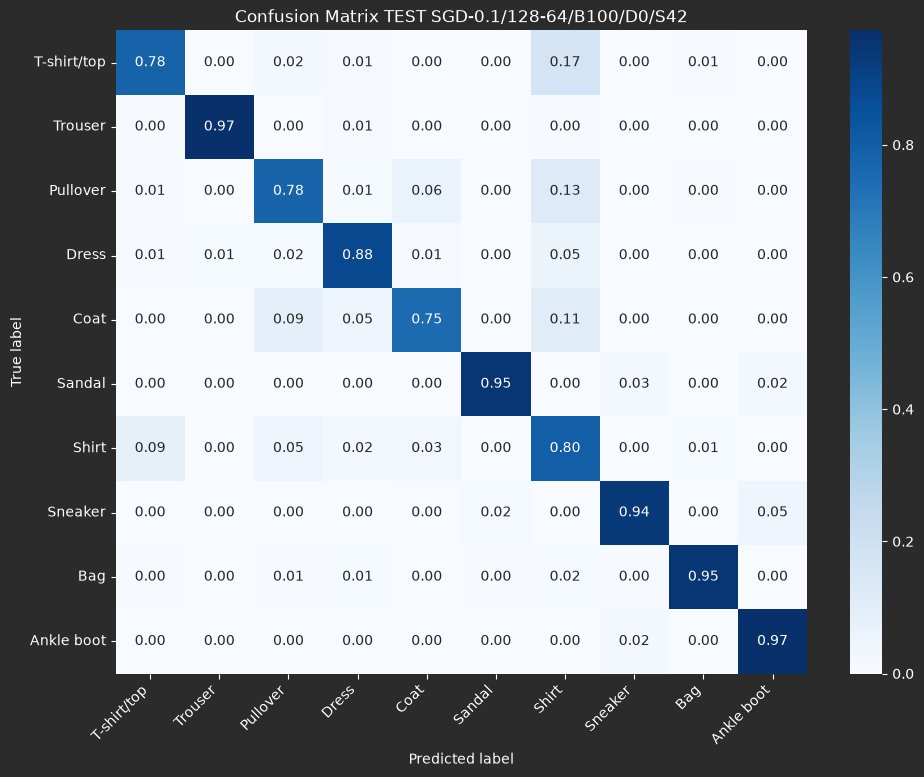

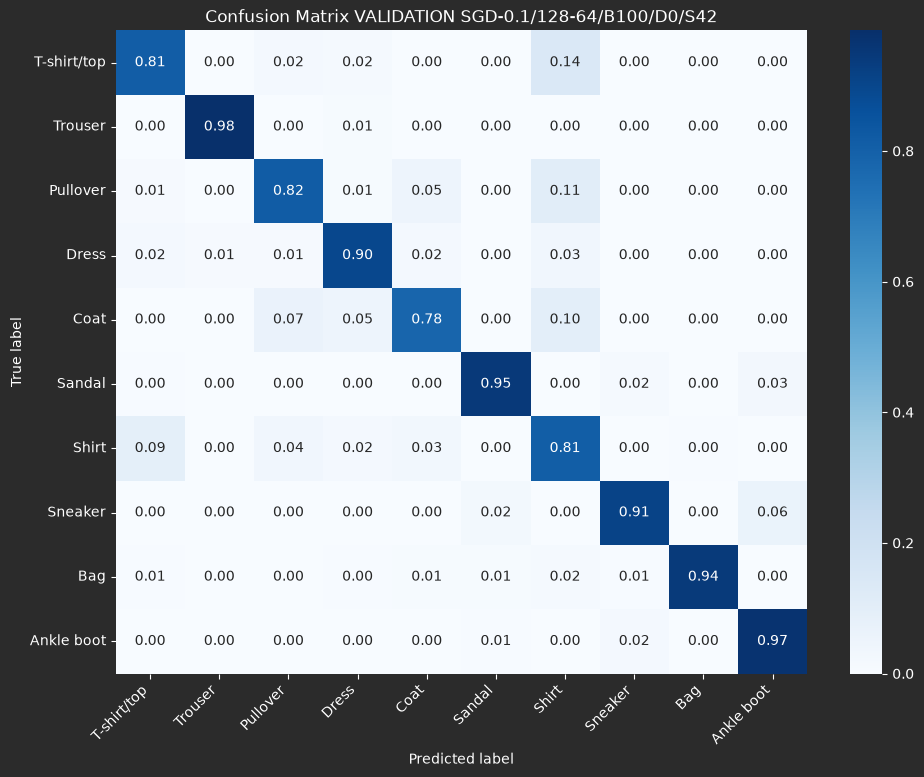


-----------------------------------Results TOGETHER:-----------------------------------


-----------------------------------GROUP: ('SGD',):-----------------------------------

----------------- SGD-0.1/128-64/B100/D0/S42 -----------------


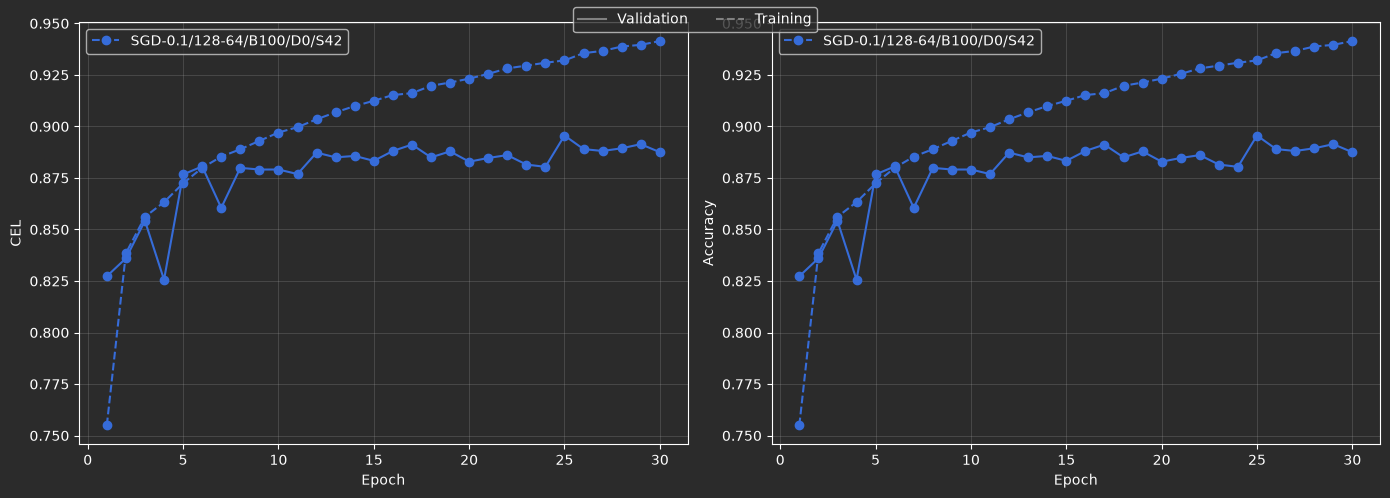

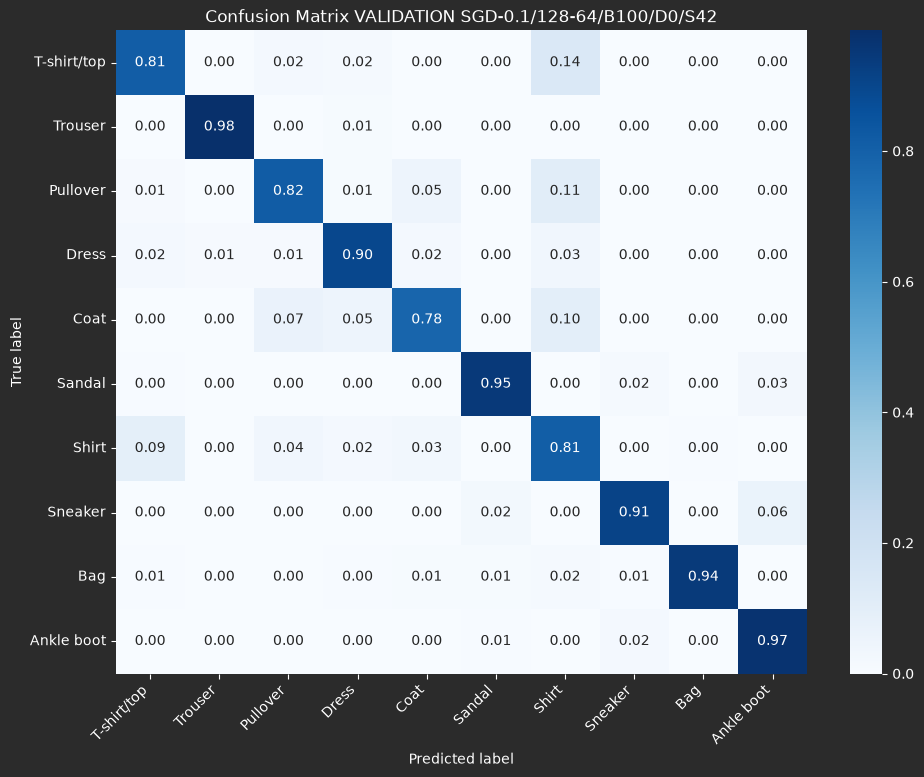

                           Train Loss Valid Loss Train Accu Valid Accu Test Accu Test Worst Class Test Worst Recall Valid Worst Class Valid Worst Recall TV gap Test CM Deviation Valid CM Deviation
SGD-0.1/128-64/B100/D0/S42      0.158      0.343      0.941      0.887     0.878             Coat             0.755              Coat              0.781  0.054             0.317              0.251

--- Best experiments ---
Max Test Accu      -> SGD-0.1/128-64/B100/D0/S42: 0.8778
Max Valid Accu     -> SGD-0.1/128-64/B100/D0/S42: 0.8875
Best Test Worst-Class Recall -> SGD-0.1/128-64/B100/D0/S42: Coat (0.7550)
Best Valid Worst-Class Recall -> SGD-0.1/128-64/B100/D0/S42: Coat (0.7813)
Min Test CM Deviation  -> SGD-0.1/128-64/B100/D0/S42: 0.3166
Min Valid CM Deviation -> SGD-0.1/128-64/B100/D0/S42: 0.2511
Min abs Generalization Gap -> SGD-0.1/128-64/B100/D0/S42: 0.053939998149871826
Max abs Generalization Gap -> SGD-0.1/128-64/B100/D0/S42: 0.053939998149871826

-----------------------------------A

In [1]:
import time
from collections import defaultdict
from itertools import product

import torch
from torch import nn

from pract11.Guia11Reformat.src.ClassifierMLP import ClassifierMLP
from pract11.Guia11Reformat.src.Config import Config
from pract11.Guia11Reformat.src.FashionMNISTData import FashionMNISTData
from pract11.Guia11Reformat.src.Optimizer import create_optimizer
from pract11.Guia11Reformat.src.Trainer import Trainer
from pract11.Guia11Reformat.src.Visualizer import Visualizer


def runExperiment(config, data):
    # Configuración
    device = config.setup()

    if config.show_sample:
        data.inspect_example()

    # Modelo
    torch.manual_seed(config.SEED)

    model = ClassifierMLP(
        p_dropout=config.DROPOUT_P, neuron_1=config.neuron_1, neuron_2=config.neuron_2,
    ).to(device)

    # Comprobar dimensiones
    if config.show_dimentions:
        images, labels = next(iter(data.train_loader))

        with torch.no_grad():
            classifications = model(images.to(device))

        print(f"images.shape: {images.shape}")
        print(f"labels.shape: {labels.shape}")

        n_params = sum(
            p.numel()
            for p in model.parameters()
            if p.requires_grad
        )
        print(f"Parámetros entrenables: {n_params:,}")

        print("\nDimensiones:")
        print("Entrada:", images.shape)
        print("Logits:", classifications.shape)

    # Función de pérdida y optimizador
    loss_fn = nn.CrossEntropyLoss()

    optimizer = create_optimizer(
        model=model,
        optimizer_name=config.OPTIMIZER_NAME,
        lr=config.LEARNING_RATE
    )

    print("\nOptimizador:", config.OPTIMIZER_NAME)
    print("Dropout:", config.DROPOUT_P)

    # Untrained
    if config.show_untrained:
        Visualizer.showPredictions(model, device, data)
    # Entrenamiento
    torch.cuda.reset_peak_memory_stats()

    trainer = Trainer(
        model,
        optimizer,
        loss_fn,
        device,
        config
    )
    start = time.perf_counter()
    trainer.fit(
        data.train_loader,
        data.valid_loader,
        epochs=config.EPOCHS
    )

    training_time = time.perf_counter() - start
    trainer.history["training_time"] = training_time
    print(f"Training time: {training_time:.2f} seconds\n")
    peak_memory = torch.cuda.max_memory_allocated() / (1024 ** 2)
    trainer.history["GPU_max_VRAM"] = peak_memory
    print(f"Peak GPU memory: {peak_memory:.2f} MB")

    # Gráfico de pérdidas
    if config.show_loss: Visualizer.plot_history(trainer.history)

    # Evaluación final
    _, _, confusion_matrix = trainer.test(data.test_loader)

    #Trained
    if config.show_trained:
        Visualizer.showPredictions(model, device, data)
    return trainer, data, confusion_matrix


# ============================================================
# EJECUCIÓN
# ============================================================

def pre_run(expies, data):
    results_together = {}
    for title, exp in expies.items():
        results = {}
        data.reset_loader(batch_size=exp.BATCH_SIZE)  # Reset seed and batch before each experiment
        trainer, data, confusion_matrix = runExperiment(exp, data)
        results[title] = {"trainer": trainer, "data": data, "confusion_matrix": confusion_matrix}
        results_together[title] = {"trainer": trainer, "data": data, "confusion_matrix": confusion_matrix,
                                   "config": exp}
        Visualizer.showExpieResults(results)
    return results_together


data_loaders = FashionMNISTData(
    batch_size=100,
    seed=42, show_dataset_info=False,
)


def viewAftermath(results_together):
    print("\n-----------------------------------Results TOGETHER:-----------------------------------\n")

    groups = defaultdict(dict)

    for title, result in results_together.items():
        config = result["config"]

        key = (
            config.OPTIMIZER_NAME,
        )

        groups[key][title] = result

    for key, group_results in groups.items():
        print(f"\n-----------------------------------GROUP: {key}:-----------------------------------\n")

        Visualizer.showExpieResults(group_results, show_confusion=False)
        Visualizer.showComparativeTable(group_results)
    print("\n-----------------------------------ALL:-----------------------------------\n")
    Visualizer.showComparativeTable(results_together)


opti = [
    # ("SGD", 0.001),
    # ("SGD", 0.01),
    ("SGD", 0.1),
    # ("Adam", 0.0001),
    # ("Adam", 0.001),
    # ("Adam", 0.01)
]

batches = [
    # 64,
    100,
    # 256,
    # 512
]

neurons = [
    # (64, 32),
    (128, 64),
    # (256, 128),
    # (512, 256)
]

dropout = [
     0,
    # 0.2,
    #  0.5
]

seeds = [42]


#i choose  SGD-0.1/128-64/B100/D0
def gen_expies(opti, batches, neurons, dropout, seeds):
    expies = {}

    for (optimizer, lr), batch, (n1, n2), drop,seed in product(
            opti, batches, neurons, dropout,seeds
    ):
        title = f"{optimizer}-{lr}/{n1}-{n2}/B{batch}/D{drop}/S{seed}"

        expies[title] = Config(
            lr=lr,
            seed=seed,
            dropout_p=drop,
            epochs=30,
            optimizer_name=optimizer,
            neuron1=n1,
            neuron2=n2,
            batch_size=batch,
        )
    print(f"\nExperiments: {len(expies)}\n")
    return expies


expies = gen_expies(opti, batches, neurons, dropout,seeds)

aftermath = pre_run(expies, data_loaders)

viewAftermath(aftermath)

import winsound
for _ in range(14):
    winsound.MessageBeep(winsound.MB_ICONEXCLAMATION)
    time.sleep(0.5)